# Bank transactions analysis with PySpark

Final project of the *Microcredential in Data Science, Big Data, AI & Business Intelligence* (University of Jaén).

The notebook builds a small ETL and analysis pipeline with **PySpark** over a synthetic dataset of about one million bank transactions (provided by the course) plus a small table of countries. It has four phases:

1. **Cleaning**: value mappings, dates, number normalization.
2. **Exploitation**: derived columns (currency conversions, fees, tariffs, local taxes, EU membership).
3. **Summary tables**: spending by country, month and domain, taxes and crisis candidates.
4. **Presentation**: six analysis questions answered with a string, plus charts and CSV exports (used later for a Power BI report).

> **About the data.** The data is synthetic. Locations are Indian cities that the assignment maps to fictional "countries", and spending per country is almost uniform. The point of the project is the pipeline, not the business conclusions. See the README for details and for the list of fixes made to the original course submission.


## 1. Setup

In [1]:
from datetime import date
from itertools import chain
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.sql.types import (BooleanType, DoubleType, IntegerType, LongType,
                               StringType, StructField, StructType)

# Paths: the notebook lives in notebooks/, data and results are siblings.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, RESULTS = ROOT / "data", ROOT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Use the full dataset if it is present, otherwise the small sample that ships with the repo.
BANK_CSV = DATA / "bankdataset.csv"
if not BANK_CSV.exists():
    BANK_CSV = DATA / "bankdataset_sample.csv"
PAISES_CSV = DATA / "paises.csv"
print("Transactions file:", BANK_CSV.relative_to(ROOT))

spark = (
    SparkSession.builder.appName("bank-transactions-analysis")
    .master("local[*]")
    .config("spark.driver.memory", "2g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Transactions file: data/bankdataset.csv


Spark 3.5.5


### Helpers

Numbers are kept as real numeric columns all the way through the pipeline. European notation (`1.234,56`), as the assignment asks, is applied only when displaying tables, with native Spark functions (no Python UDFs). The text answers in section 6 use standard English notation.

In [2]:
def eu(column, decimals=2):
    """Format a numeric column with European notation (1.234,56) for display only."""
    return F.translate(F.format_number(column, decimals), ",.", ".,")


def fmt_num(value, decimals=2):
    """Format a plain Python number for the text answers (1,234.56)."""
    return f"{value:,.{decimals}f}"


def to_pd(df):
    """Collect a small Spark DataFrame into pandas."""
    return pd.DataFrame([row.asDict() for row in df.collect()])


def map_column(df, source, target, mapping):
    """Add `target` by mapping the values of `source`, and fail if any value is not covered."""
    expr = F.create_map([F.lit(x) for x in chain(*mapping.items())])
    out = df.withColumn(target, expr[F.col(source)])
    missing = out.filter(F.col(target).isNull()).count()
    assert missing == 0, f"{missing} rows could not be mapped from {source}"
    return out

## 2. Loading the data

In [3]:
bank_schema = StructType([
    StructField("Date", StringType()),
    StructField("Domain", StringType()),
    StructField("Location", StringType()),
    StructField("Value", LongType()),
    StructField("Transaction_count", LongType()),
    StructField("Key", IntegerType()),
])
bank_df = spark.read.csv(str(BANK_CSV), header=True, sep=";", schema=bank_schema)
print(f"{bank_df.count():,} transactions")
bank_df.show(5)

1,004,480 transactions


+----------+-------------+--------+------+-----------------+---+
|      Date|       Domain|Location| Value|Transaction_count|Key|
+----------+-------------+--------+------+-----------------+---+
|01/01/2022|    RESTRAUNT|    Bhuj|365554|             1932|  1|
|01/01/2022|  INVESTMENTS|Ludhiana|847444|             1721|  3|
|01/01/2022|       RETAIL|     Goa|786941|             1573|  2|
|01/01/2022|INTERNATIONAL| Mathura|368610|             2049|  1|
|01/01/2022|    RESTRAUNT| Madurai|615681|             1519|  1|
+----------+-------------+--------+------+-----------------+---+
only showing top 5 rows



In [4]:
paises_schema = StructType([
    StructField("ID", IntegerType()),
    StructField("País", StringType()),
    StructField("Impuestos_Locales", DoubleType()),
    StructField("Situación_de_Crisis", StringType()),
])
paises_df = (
    spark.read.csv(str(PAISES_CSV), header=True, sep=";", schema=paises_schema)
    .withColumn("Situación_de_Crisis", F.col("Situación_de_Crisis").cast(BooleanType()))
)
paises_df.show(5)

+---+---------+-----------------+-------------------+
| ID|     País|Impuestos_Locales|Situación_de_Crisis|
+---+---------+-----------------+-------------------+
|  1|   España|            12.38|               true|
|  2|Argentina|             5.74|              false|
|  3|   Brasil|            10.51|               true|
|  4|   México|             3.27|              false|
|  5|     Perú|             8.93|               true|
+---+---------+-----------------+-------------------+
only showing top 5 rows



## 3. Cleaning

### 3.1 Location to country

The assignment gives a table that maps each location to a country. Its names for a few countries have no spaces (for example `CoreadelSur`), while `paises.csv` writes them with spaces (`Corea del Sur`). Joining with those names silently drops 8 countries, so the mapping below uses the names of `paises.csv`. `map_column` fails if any row is left unmapped.

In [5]:
LOCATION_TO_COUNTRY = {
    "Bhuj": "España", "Ludhiana": "Argentina", "Goa": "Brasil", "Mathura": "México",
    "Madurai": "Perú", "Daman": "Canadá", "Buxar": "Australia", "Trichy": "Marruecos",
    "Kullu": "Corea del Sur", "Hyderabad": "Nueva Zelanda", "Lucknow": "Alemania",
    "Bikaner": "Francia", "Amritsar": "Chile", "Doda": "Suecia", "Jaipur": "Noruega",
    "Kannur": "Grecia", "Lunglei": "Colombia", "Bombay": "Italia", "Pune": "Sudáfrica",
    "Ajmer": "Tailandia", "Bhind": "Japón", "Akola": "Finlandia", "Kanpur": "Portugal",
    "Bhopal": "Turquía", "Vellore": "Vietnam", "Surat": "Egipto", "Ranchi": "Islandia",
    "Banglore": "Polonia", "Tirumala": "República Checa", "Bokaro": "Hungría",
    "Ambala": "Ucrania", "Ara": "Arabia Saudita", "Konark": "Emiratos Árabes Unidos",
    "Betul": "Filipinas", "Patiala": "Indonesia", "Ahmedabad": "Nigeria",
    "Bidar": "Venezuela", "Indore": "Bolivia", "Srinagar": "Uruguay", "Kolkata": "Paraguay",
    "Durg": "Nicaragua", "Kochin": "Panamá", "Kota": "Costa Rica",
    "Delhi": "República Dominicana", "Mon": "Cuba", "Varanasi": "El Salvador",
}

df = map_column(bank_df, "Location", "País", LOCATION_TO_COUNTRY)

# Every country must exist in paises.csv, otherwise the join in 4.6 would lose rows.
country_names = {r["País"] for r in paises_df.select("País").collect()}
assert set(LOCATION_TO_COUNTRY.values()) <= country_names, "country names do not match paises.csv"
df.select("Location", "País").distinct().show(5)

+--------+---------+
|Location|     País|
+--------+---------+
| Mathura|   México|
|   Akola|Finlandia|
|  Bhopal|  Turquía|
| Vellore|  Vietnam|
|   Betul|Filipinas|
+--------+---------+
only showing top 5 rows



### 3.2 Domain translation

In [6]:
DOMAIN_TO_SPANISH = {   # "RESTRAUNT" is the spelling used in the source data
    "EDUCATION": "Educación", "INTERNATIONAL": "Internacional", "INVESTMENTS": "Inversiones",
    "MEDICAL": "Medicina", "PUBLIC": "Público", "RESTRAUNT": "Restaurantes", "RETAIL": "Ventas",
}
df = map_column(df, "Domain", "Dominio", DOMAIN_TO_SPANISH)
df.select("Domain", "Dominio").distinct().show()

+-------------+-------------+
|       Domain|      Dominio|
+-------------+-------------+
|INTERNATIONAL|Internacional|
|    RESTRAUNT| Restaurantes|
|  INVESTMENTS|  Inversiones|
|      MEDICAL|     Medicina|
|       RETAIL|       Ventas|
|    EDUCATION|    Educación|
|       PUBLIC|      Público|
+-------------+-------------+



### 3.3 Dates

`Date` becomes a real date type. The assignment asks for the `MM-dd-yyyy` format, which is kept in `Date_MMDDYYYY` for display.

In [7]:
df = (
    df.withColumn("Date", F.to_date("Date", "dd/MM/yyyy"))
    .withColumn("Date_MMDDYYYY", F.date_format("Date", "MM-dd-yyyy"))
)
assert df.filter(F.col("Date").isNull()).count() == 0, "some dates could not be parsed"
df.select("Date", "Date_MMDDYYYY").show(3)

+----------+-------------+
|      Date|Date_MMDDYYYY|
+----------+-------------+
|2022-01-01|   01-01-2022|
|2022-01-01|   01-01-2022|
|2022-01-01|   01-01-2022|
+----------+-------------+
only showing top 3 rows



### 3.4 Numeric normalization

The assignment's rules: a value with 3 or more digits has two decimals (the raw number is in cents), a value with 2 digits or fewer is unchanged, and zero stays zero. `Value` is then an amount in euros. `Transaction_count` is an integer with no decimals.

In [8]:
df = df.withColumn(
    "Value",
    F.when(F.col("Value") >= 100, F.col("Value") / 100).otherwise(F.col("Value").cast("double")),
)
df.select("Value", "Transaction_count").describe().show()

+-------+------------------+-----------------+
|summary|             Value|Transaction_count|
+-------+------------------+-----------------+
|  count|           1004480|          1004480|
|   mean|7498.4779483115235|1473.807652715833|
| stddev| 2609.129395249399|620.3409414731748|
|    min|           2984.23|              400|
|    max|          12022.71|             2548|
+-------+------------------+-----------------+



### 3.5 Transaction type

In [9]:
KEY_TO_TYPE = {1: "transaccion_bancaria", 2: "bizum", 3: "pago_en_metalico"}
df = map_column(df, "Key", "Tipo_Transaccion", KEY_TO_TYPE)
df = df.drop("Location", "Domain", "Key")
df.show(5)

+----------+-------+-----------------+---------+-------------+-------------+--------------------+
|      Date|  Value|Transaction_count|     País|      Dominio|Date_MMDDYYYY|    Tipo_Transaccion|
+----------+-------+-----------------+---------+-------------+-------------+--------------------+
|2022-01-01|3655.54|             1932|   España| Restaurantes|   01-01-2022|transaccion_bancaria|
|2022-01-01|8474.44|             1721|Argentina|  Inversiones|   01-01-2022|    pago_en_metalico|
|2022-01-01|7869.41|             1573|   Brasil|       Ventas|   01-01-2022|               bizum|
|2022-01-01| 3686.1|             2049|   México|Internacional|   01-01-2022|transaccion_bancaria|
|2022-01-01|6156.81|             1519|     Perú| Restaurantes|   01-01-2022|transaccion_bancaria|
+----------+-------+-----------------+---------+-------------+-------------+--------------------+
only showing top 5 rows



## 4. Exploitation: derived columns

### 4.1 Currency conversion

`Value` is in euros. Rates given by the assignment: 1 USD = 0,88 EUR, 1 JPY = 0,0061 EUR, 1 INR = 0,010 EUR.

In [10]:
EUR_PER_UNIT = {"USD": 0.88, "JPY": 0.0061, "INR": 0.010}

for currency, rate in EUR_PER_UNIT.items():
    df = df.withColumn(f"Value_{currency}", F.col("Value") / F.lit(rate))

df.select(eu("Value").alias("Value_EUR"),
          *[eu(f"Value_{c}").alias(f"Value_{c}") for c in EUR_PER_UNIT]).show(3)

+---------+---------+------------+----------+
|Value_EUR|Value_USD|   Value_JPY| Value_INR|
+---------+---------+------------+----------+
| 3.655,54| 4.154,02|  599.268,85|365.554,00|
| 8.474,44| 9.630,05|1.389.252,46|847.444,00|
| 7.869,41| 8.942,51|1.290.067,21|786.941,00|
+---------+---------+------------+----------+
only showing top 3 rows



### 4.2 Average amount per transaction and 4.3 management costs

`Total_Gastos_Gestion = media * n_transacciones + media * n_transacciones * comisión(tipo)`, as defined in the assignment. Commissions: bank transaction 0,05 %, bizum 0,01 %, cash 0 %. Note that, by this definition, the column contains the whole amount plus the commission, not only the commission.

In [11]:
COMMISSION = {"transaccion_bancaria": 0.0005, "bizum": 0.0001, "pago_en_metalico": 0.0}
commission_expr = F.create_map([F.lit(x) for x in chain(*COMMISSION.items())])[F.col("Tipo_Transaccion")]

df = df.withColumn("Media_Importe_Transaccion", F.col("Value") / F.col("Transaction_count"))
base = F.col("Media_Importe_Transaccion") * F.col("Transaction_count")
df = df.withColumn("Total_Gastos_Gestion", base + base * commission_expr)

df.select("Tipo_Transaccion", eu("Value").alias("Value"),
          eu("Media_Importe_Transaccion", 4).alias("Media"),
          eu("Total_Gastos_Gestion").alias("Total_Gastos_Gestion")).show(5)

+--------------------+--------+------+--------------------+
|    Tipo_Transaccion|   Value| Media|Total_Gastos_Gestion|
+--------------------+--------+------+--------------------+
|transaccion_bancaria|3.655,54|1,8921|            3.657,37|
|    pago_en_metalico|8.474,44|4,9241|            8.474,44|
|               bizum|7.869,41|5,0028|            7.870,20|
|transaccion_bancaria|3.686,10|1,7990|            3.687,94|
|transaccion_bancaria|6.156,81|4,0532|            6.159,89|
+--------------------+--------+------+--------------------+
only showing top 5 rows



### 4.4 European Union membership and 4.5 tariffs

`UE` is true for the 27 member states. Countries outside the EU pay a 10 % tariff on `Value`.

In [12]:
EU_COUNTRIES = [
    "Alemania", "Austria", "Bélgica", "Bulgaria", "Croacia", "Chipre", "República Checa",
    "Dinamarca", "Eslovaquia", "Eslovenia", "España", "Estonia", "Finlandia", "Francia",
    "Grecia", "Hungría", "Irlanda", "Italia", "Letonia", "Lituania", "Luxemburgo", "Malta",
    "Países Bajos", "Polonia", "Portugal", "Rumanía", "Suecia",
]
assert len(EU_COUNTRIES) == 27

df = df.withColumn("UE", F.col("País").isin(EU_COUNTRIES))
df = df.withColumn("Aranceles", F.when(F.col("UE"), F.lit(0.0)).otherwise(F.col("Value") * 0.10))

df.select("País", "UE").distinct().filter("UE").orderBy("País").show()

+---------------+----+
|           País|  UE|
+---------------+----+
|       Alemania|true|
|         España|true|
|      Finlandia|true|
|        Francia|true|
|         Grecia|true|
|        Hungría|true|
|         Italia|true|
|        Polonia|true|
|       Portugal|true|
|República Checa|true|
|         Suecia|true|
+---------------+----+



### 4.6 Local taxes (join with the countries table)

The join must not lose any row: after it, no country may have a missing tax rate or crisis flag.

In [13]:
paises_cols = paises_df.select("País", "ID", "Impuestos_Locales", "Situación_de_Crisis")
df = df.join(F.broadcast(paises_cols), on="País", how="left")

unmatched = df.filter(F.col("Impuestos_Locales").isNull() | F.col("Situación_de_Crisis").isNull()).count()
assert unmatched == 0, f"{unmatched} rows have no match in paises.csv"

df = df.withColumn("Total_Impuestos_Locales", F.col("Value") * F.col("Impuestos_Locales") / 100)
df.select("País", "Impuestos_Locales", eu("Value").alias("Value"),
          eu("Total_Impuestos_Locales").alias("Total_Impuestos_Locales")).show(5)

+---------+-----------------+--------+-----------------------+
|     País|Impuestos_Locales|   Value|Total_Impuestos_Locales|
+---------+-----------------+--------+-----------------------+
|   España|            12.38|3.655,54|                 452,56|
|Argentina|             5.74|8.474,44|                 486,43|
|   Brasil|            10.51|7.869,41|                 827,07|
|   México|             3.27|3.686,10|                 120,54|
|     Perú|             8.93|6.156,81|                 549,80|
+---------+-----------------+--------+-----------------------+
only showing top 5 rows



### 4.7 Countries that could join the EU

Following the truth table of the assignment (UE, crisis, Nueva_UE): the result is true exactly when the country is not in crisis.

In [14]:
df = df.withColumn("Nueva_UE", ~F.col("Situación_de_Crisis"))
df.select("UE", "Situación_de_Crisis", "Nueva_UE").distinct().orderBy("UE", "Situación_de_Crisis").show()

+-----+-------------------+--------+
|   UE|Situación_de_Crisis|Nueva_UE|
+-----+-------------------+--------+
|false|              false|    true|
|false|               true|   false|
| true|              false|    true|
| true|               true|   false|
+-----+-------------------+--------+



### 4.8 Management costs in the three currencies

In [15]:
for currency, rate in EUR_PER_UNIT.items():
    df = df.withColumn(f"Total_Gastos_Gestion_{currency}", F.col("Total_Gastos_Gestion") / F.lit(rate))

df.printSchema()

root
 |-- País: string (nullable = true)
 |-- Date: date (nullable = true)
 |-- Value: double (nullable = true)
 |-- Transaction_count: long (nullable = true)
 |-- Dominio: string (nullable = true)
 |-- Date_MMDDYYYY: string (nullable = true)
 |-- Tipo_Transaccion: string (nullable = true)
 |-- Value_USD: double (nullable = true)
 |-- Value_JPY: double (nullable = true)
 |-- Value_INR: double (nullable = true)
 |-- Media_Importe_Transaccion: double (nullable = true)
 |-- Total_Gastos_Gestion: double (nullable = true)
 |-- UE: boolean (nullable = true)
 |-- Aranceles: double (nullable = true)
 |-- ID: integer (nullable = true)
 |-- Impuestos_Locales: double (nullable = true)
 |-- Situación_de_Crisis: boolean (nullable = true)
 |-- Total_Impuestos_Locales: double (nullable = true)
 |-- Nueva_UE: boolean (nullable = true)
 |-- Total_Gastos_Gestion_USD: double (nullable = true)
 |-- Total_Gastos_Gestion_JPY: double (nullable = true)
 |-- Total_Gastos_Gestion_INR: double (nullable = true)



## 5. Summary DataFrames

### 5.1 Joined DataFrame

`big_df` is the transactions table joined with the countries table. It is cached because every query below reads it.

In [16]:
big_df = df.persist(StorageLevel.MEMORY_AND_DISK)
print(f"{big_df.count():,} rows, {len(big_df.columns)} columns")
assert big_df.select(F.year("Date")).distinct().count() == 1, "monthly queries assume a single year"
big_df.select("Date_MMDDYYYY", "País", "Dominio", "Tipo_Transaccion", eu("Value").alias("Value"),
              "Impuestos_Locales", "Situación_de_Crisis", "UE").show(5)

1,004,480 rows, 22 columns


+-------------+---------+-------------+--------------------+--------+-----------------+-------------------+-----+
|Date_MMDDYYYY|     País|      Dominio|    Tipo_Transaccion|   Value|Impuestos_Locales|Situación_de_Crisis|   UE|
+-------------+---------+-------------+--------------------+--------+-----------------+-------------------+-----+
|   01-01-2022|   España| Restaurantes|transaccion_bancaria|3.655,54|            12.38|               true| true|
|   01-01-2022|Argentina|  Inversiones|    pago_en_metalico|8.474,44|             5.74|              false|false|
|   01-01-2022|   Brasil|       Ventas|               bizum|7.869,41|            10.51|               true|false|
|   01-01-2022|   México|Internacional|transaccion_bancaria|3.686,10|             3.27|              false|false|
|   01-01-2022|     Perú| Restaurantes|transaccion_bancaria|6.156,81|             8.93|               true|false|
+-------------+---------+-------------+--------------------+--------+-----------------+-

### 5.2 Spending by country, month, country and month, and domain

In [17]:
country_total_value_df = (
    big_df.groupBy("País").agg(F.sum("Value").alias("Gasto_Acumulado"))
    .orderBy(F.col("Gasto_Acumulado").desc())
)
month_total_value_df = (
    big_df.groupBy(F.month("Date").alias("Mes")).agg(F.sum("Value").alias("Gasto_Acumulado"))
    .orderBy("Mes")
)
month_country_total_value = (
    big_df.groupBy("País", F.month("Date").alias("Mes")).agg(F.sum("Value").alias("Gasto_Acumulado"))
    .orderBy("País", "Mes")
)
domain_total_value = (
    big_df.groupBy("Dominio").agg(F.sum("Value").alias("Gasto_Acumulado"))
    .orderBy(F.col("Gasto_Acumulado").desc())
)

for name, frame in [("By country (top 5)", country_total_value_df.limit(5)),
                    ("By month", month_total_value_df),
                    ("By domain", domain_total_value)]:
    print(name)
    frame.select(*[c for c in frame.columns if c != "Gasto_Acumulado"],
                 eu("Gasto_Acumulado").alias("Gasto_Acumulado")).show(12)

By country (top 5)


+---------+---------------+
|     País|Gasto_Acumulado|
+---------+---------------+
|  Turquía| 165.543.945,44|
|Nicaragua| 165.161.025,19|
|   España| 165.145.343,45|
|  Hungría| 165.074.751,72|
|Indonesia| 164.959.968,19|
+---------+---------------+

By month


+---+---------------+
|Mes|Gasto_Acumulado|
+---+---------------+
|  1| 639.672.359,67|
|  2| 576.989.862,13|
|  3| 638.768.847,69|
|  4| 617.630.547,48|
|  5| 640.153.829,61|
|  6| 619.323.187,45|
|  7| 640.495.933,78|
|  8| 640.898.982,37|
|  9| 619.111.901,01|
| 10| 639.867.421,81|
| 11| 619.276.066,68|
| 12| 639.882.189,84|
+---+---------------+

By domain


+-------------+----------------+
|      Dominio| Gasto_Acumulado|
+-------------+----------------+
|      Público|1.077.914.329,24|
|     Medicina|1.077.909.807,56|
|Internacional|1.077.243.964,47|
|    Educación|1.076.587.043,94|
|  Inversiones|1.076.135.928,21|
| Restaurantes|1.074.984.993,45|
|       Ventas|1.071.295.062,65|
+-------------+----------------+



### 5.3 Top 3 EU countries by taxes paid

The assignment defines the taxes as the sum of `Total_Gastos_Gestion`, `Aranceles` and `Total_Impuestos_Locales`. Because `Total_Gastos_Gestion` includes the whole amount (see 4.3), it dominates the total, and EU countries pay no tariffs. The ranking therefore follows total spending more than taxes.

In [18]:
top3_eu_taxes_df = (
    big_df.filter("UE").groupBy("País")
    .agg(F.sum("Total_Gastos_Gestion").alias("Total_Gastos_Gestion"),
         F.sum("Aranceles").alias("Total_Aranceles"),
         F.sum("Total_Impuestos_Locales").alias("Total_Impuestos_Locales"))
    .withColumn("Total_Impuestos",
                F.col("Total_Gastos_Gestion") + F.col("Total_Aranceles") + F.col("Total_Impuestos_Locales"))
    .orderBy(F.col("Total_Impuestos").desc())
    .limit(3)
)
top3_eu_taxes_df.select("País", eu("Total_Impuestos").alias("Total_Impuestos")).show()

+-------+---------------+
|   País|Total_Impuestos|
+-------+---------------+
|Francia| 186.281.045,56|
| España| 185.623.483,50|
| Italia| 182.504.279,90|
+-------+---------------+



### 5.4 Countries that could be in crisis

Criterion of the assignment: local taxes above 10 % and a total `Value` above one million. With this dataset every country spends more than one million, so only the tax criterion filters.

In [19]:
country_possible_crisis_df = (
    big_df.groupBy("País", "Impuestos_Locales").agg(F.sum("Value").alias("Total_Value"))
    .where((F.col("Impuestos_Locales") > 10) & (F.col("Total_Value") > 1_000_000))
    .orderBy(F.col("Impuestos_Locales").desc())
)
country_possible_crisis_df.select("País", "Impuestos_Locales", eu("Total_Value").alias("Total_Value")).show(30)

+--------------------+-----------------+--------------+
|                País|Impuestos_Locales|   Total_Value|
+--------------------+-----------------+--------------+
|             Francia|            14.89|162.110.423,48|
|            Islandia|            13.99|164.184.278,34|
|             Noruega|            13.41|163.197.306,03|
|           Australia|            13.08|161.488.606,78|
|               Japón|            12.61|164.020.813,40|
|              España|            12.38|165.145.343,45|
|República Dominicana|            11.94|163.291.356,04|
|            Alemania|            11.67|162.264.142,97|
|              Italia|            11.23|164.048.584,70|
|              Suecia|            10.77|164.195.779,86|
|              Brasil|            10.51|164.299.201,51|
|            Portugal|            10.39|163.494.042,98|
|          Costa Rica|            10.11|163.718.987,08|
+--------------------+-----------------+--------------+



## 6. Presentation: six analysis questions

Each query returns a string. The numbers come from the DataFrames above.

### 6.1 What is the difference between the month with the highest and the lowest spending?

In [20]:
MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]

def monthly_spending_gap():
    rows = month_total_value_df.orderBy(F.col("Gasto_Acumulado").desc()).collect()
    top, bottom = rows[0], rows[-1]
    gap = top["Gasto_Acumulado"] - bottom["Gasto_Acumulado"]
    return (f"The gap between the highest month ({MONTHS[top['Mes'] - 1]}, {fmt_num(top['Gasto_Acumulado'])} €) "
            f"and the lowest ({MONTHS[bottom['Mes'] - 1]}, {fmt_num(bottom['Gasto_Acumulado'])} €) "
            f"is {fmt_num(gap)} €.")

answer_1 = monthly_spending_gap()
print(answer_1)

The gap between the highest month (August, 640,898,982.37 €) and the lowest (February, 576,989,862.13 €) is 63,909,120.24 €.


### 6.2 Which country has the highest spending per transaction among the countries that are not in crisis?

In [21]:
def highest_ratio_without_crisis():
    row = (
        big_df.filter(~F.col("Situación_de_Crisis")).groupBy("País")
        .agg((F.sum("Value") / F.sum("Transaction_count")).alias("Ratio"))
        .orderBy(F.col("Ratio").desc()).first()
    )
    return (f"Among the countries not in crisis, {row['País']} has the highest spending per "
            f"transaction: {fmt_num(row['Ratio'])} €.")

answer_2 = highest_ratio_without_crisis()
print(answer_2)

Among the countries not in crisis, Argentina has the highest spending per transaction: 5.13 €.


### 6.3 What percentage of the international transactions in countries with local taxes above 12 % cost more to manage than the European average?

In [22]:
def international_above_eu_average():
    eu_average = big_df.filter("UE").agg(F.avg("Total_Gastos_Gestion")).first()[0]
    subset = big_df.filter((F.col("Dominio") == "Internacional") & (F.col("Impuestos_Locales") > 12))
    total = subset.count()
    above = subset.filter(F.col("Total_Gastos_Gestion") > eu_average).count()
    return (f"{above / total * 100:.2f} % of the {total:,} international transactions in countries with "
            f"local taxes above 12 % have management costs above the EU average ({fmt_num(eu_average)} €).")

answer_3 = international_above_eu_average()
print(answer_3)

49.53 % of the 18,654 international transactions in countries with local taxes above 12 % have management costs above the EU average (7,494.63 €).


### 6.4 How does the quarterly efficiency ratio of each domain evolve compared with the previous quarter, in European countries?

Efficiency is `total value / total management costs`, as defined in the assignment. Since the management costs are the value plus a very small commission, the ratio is always close to 1 and changes only with the mix of transaction types.

In [23]:
quarterly_window = Window.partitionBy("Dominio").orderBy("Trimestre")
quarterly_efficiency_df = (
    big_df.filter("UE")
    .groupBy(F.quarter("Date").alias("Trimestre"), "Dominio")
    .agg((F.sum("Value") / F.sum("Total_Gastos_Gestion")).alias("Eficiencia"))
    .withColumn("Variacion_Pct",
                (F.col("Eficiencia") / F.lag("Eficiencia").over(quarterly_window) - 1) * 100)
    .orderBy("Dominio", "Trimestre")
)
quarterly_efficiency_df.show(30)

def quarterly_efficiency_change():
    row = (quarterly_efficiency_df.filter(F.col("Variacion_Pct").isNotNull())
           .orderBy(F.abs("Variacion_Pct").desc()).first())
    return (f"The largest quarter-on-quarter change in efficiency is in {row['Dominio']}: "
            f"{row['Variacion_Pct']:+.4f} % in quarter {row['Trimestre']} compared with quarter "
            f"{row['Trimestre'] - 1} (ratio {row['Eficiencia']:.5f}). The ratio stays very close to 1 "
            f"in every domain and quarter.")

answer_4 = quarterly_efficiency_change()
print(answer_4)

+---------+-------------+------------------+--------------------+
|Trimestre|      Dominio|        Eficiencia|       Variacion_Pct|
+---------+-------------+------------------+--------------------+
|        1|    Educación|0.9998029245975592|                NULL|
|        2|    Educación|0.9997996163117661|-3.30893790334574...|
|        3|    Educación| 0.999799050211032|-5.66214194197556...|
|        4|    Educación|0.9998016636690819|2.613983329347036E-4|
|        1|Internacional| 0.999802544978694|                NULL|
|        2|Internacional|0.9998017812300957|-7.63899434153003...|
|        3|Internacional|0.9997994273317251|-2.35436504991692...|
|        4|Internacional|0.9997985010424982|-9.26475052454023...|
|        1|  Inversiones| 0.999800850927216|                NULL|
|        2|  Inversiones|0.9998057382332136|4.888279493853176E-4|
|        3|  Inversiones|0.9998032989973594|-2.43970979652008...|
|        4|  Inversiones|0.9998009992436525|-2.30020615976656...|
|        1

The largest quarter-on-quarter change in efficiency is in Restaurantes: -0.0007 % in quarter 2 compared with quarter 1 (ratio 0.99980). The ratio stays very close to 1 in every domain and quarter.


### 6.5 Which non-crisis country shows the highest crisis risk, based on its international transactions, its tax ratio and its average spending per transaction in the last 3 months?

This is a **heuristic ranking, not a probability**: with no crisis history in the data there is nothing to train a model on. The three indicators are scaled to 0-1 across the non-crisis countries and combined with fixed weights (0,40 international share, 0,35 local taxes, 0,25 average spending per transaction). The weights are an arbitrary choice.

In [24]:
WEIGHTS = {"Ratio_Internacional": 0.40, "Impuestos_Locales": 0.35, "Gasto_Medio": 0.25}

def crisis_risk_ranking():
    last_date = big_df.agg(F.max("Date")).first()[0]
    window_start = (pd.Timestamp(last_date).to_period("M") - 2).start_time.date()
    indicators = to_pd(
        big_df.filter((F.col("Date") >= F.lit(window_start)) & ~F.col("Situación_de_Crisis"))
        .groupBy("País")
        .agg((F.sum(F.when(F.col("Dominio") == "Internacional", F.col("Value")).otherwise(0.0))
              / F.sum("Value")).alias("Ratio_Internacional"),
             F.first("Impuestos_Locales").alias("Impuestos_Locales"),
             (F.sum("Value") / F.sum("Transaction_count")).alias("Gasto_Medio"))
    )
    scaled = (indicators[list(WEIGHTS)] - indicators[list(WEIGHTS)].min()) / (
        indicators[list(WEIGHTS)].max() - indicators[list(WEIGHTS)].min())
    indicators["Indice_Riesgo"] = sum(scaled[name] * weight for name, weight in WEIGHTS.items())
    return indicators.sort_values("Indice_Riesgo", ascending=False).reset_index(drop=True), window_start

risk_df, risk_window_start = crisis_risk_ranking()
print(risk_df.head(5).round(4).to_string(index=False))
top = risk_df.iloc[0]
answer_5 = (f"Using data since {risk_window_start}, the non-crisis country with the highest risk index "
            f"is {top['País']} ({top['Indice_Riesgo']:.2f} on a 0-1 scale). This is a heuristic "
            f"ranking, not a probability.")
print(answer_5)

     País  Ratio_Internacional  Impuestos_Locales  Gasto_Medio  Indice_Riesgo
Australia               0.1440              13.08       5.1317         0.7406
    Japón               0.1469              12.61       5.0848         0.7082
 Portugal               0.1512              10.39       5.0646         0.7050
  Noruega               0.1422              13.41       5.1155         0.6830
 Islandia               0.1401              13.99       5.1274         0.6755
Using data since 2022-10-01, the non-crisis country with the highest risk index is Australia (0.74 on a 0-1 scale). This is a heuristic ranking, not a probability.


### 6.6 What is the volatility index of each domain, based on its monthly spending variations?

Volatility is the standard deviation of the month-on-month percentage change in a domain's total spending. The average number of transactions per month is shown for context.

In [25]:
monthly_domain = (
    big_df.groupBy("Dominio", F.month("Date").alias("Mes"))
    .agg(F.sum("Value").alias("Gasto_Mensual"), F.sum("Transaction_count").alias("Transacciones_Mes"))
)
domain_window = Window.partitionBy("Dominio").orderBy("Mes")
domain_volatility_df = (
    monthly_domain
    .withColumn("Variacion_Pct",
                (F.col("Gasto_Mensual") / F.lag("Gasto_Mensual").over(domain_window) - 1) * 100)
    .groupBy("Dominio")
    .agg(F.stddev("Variacion_Pct").alias("Indice_Volatilidad"),
         F.avg("Transacciones_Mes").alias("Media_Transacciones_Mes"))
    .orderBy(F.col("Indice_Volatilidad").desc())
)
domain_volatility_df.select("Dominio", F.round("Indice_Volatilidad", 3).alias("Indice_Volatilidad"),
                            eu("Media_Transacciones_Mes", 0).alias("Media_Transacciones_Mes")).show()

top_vol = domain_volatility_df.first()
answer_6 = (f"The most volatile domain is {top_vol['Dominio']}, with a month-on-month standard deviation of "
            f"{top_vol['Indice_Volatilidad']:.2f} percentage points.")
print(answer_6)

+-------------+------------------+-----------------------+
|      Dominio|Indice_Volatilidad|Media_Transacciones_Mes|
+-------------+------------------+-----------------------+
|       Ventas|             7.043|             17.553.585|
|  Inversiones|             6.535|             17.627.698|
|      Público|             6.107|             17.684.540|
| Restaurantes|             5.656|             17.602.728|
|     Medicina|             5.018|             17.598.842|
|Internacional|             4.914|             17.678.961|
|    Educación|             4.521|             17.621.173|
+-------------+------------------+-----------------------+



The most volatile domain is Ventas, with a month-on-month standard deviation of 7.04 percentage points.


## 7. Export for Power BI and for the repository

Each result is written as one CSV file with plain numbers (comma separator, dot decimals), ready to be imported in Power BI. The six answers are saved in a text file.

In [26]:
tables = {
    "gastos_por_pais": country_total_value_df,
    "gastos_por_mes": month_total_value_df,
    "gastos_por_pais_mes": month_country_total_value,
    "gastos_por_dominio": domain_total_value,
    "top3_paises_impuestos": top3_eu_taxes_df,
    "paises_crisis": country_possible_crisis_df,
    "eficiencia_trimestral": quarterly_efficiency_df,
    "volatilidad_dominio": domain_volatility_df,
}
exported = {}
for name, frame in tables.items():
    pdf = to_pd(frame)
    pdf.round(6).to_csv(RESULTS / f"{name}.csv", index=False, encoding="utf-8")
    exported[name] = pdf
risk_df.round(6).to_csv(RESULTS / "indice_riesgo_paises.csv", index=False, encoding="utf-8")

answers = [answer_1, answer_2, answer_3, answer_4, answer_5, answer_6]
(RESULTS / "respuestas.txt").write_text(
    "\n\n".join(f"{i}. {text}" for i, text in enumerate(answers, 1)) + "\n", encoding="utf-8")
print(sorted(p.name for p in RESULTS.glob("*")))

['eficiencia_trimestral.csv', 'figures', 'gastos_por_dominio.csv', 'gastos_por_mes.csv', 'gastos_por_pais.csv', 'gastos_por_pais_mes.csv', 'indice_riesgo_paises.csv', 'paises_crisis.csv', 'respuestas.txt', 'top3_paises_impuestos.csv', 'volatilidad_dominio.csv']


## 8. Charts

Charts are drawn from the exported results. The y-axes start at zero so that differences are not exaggerated.

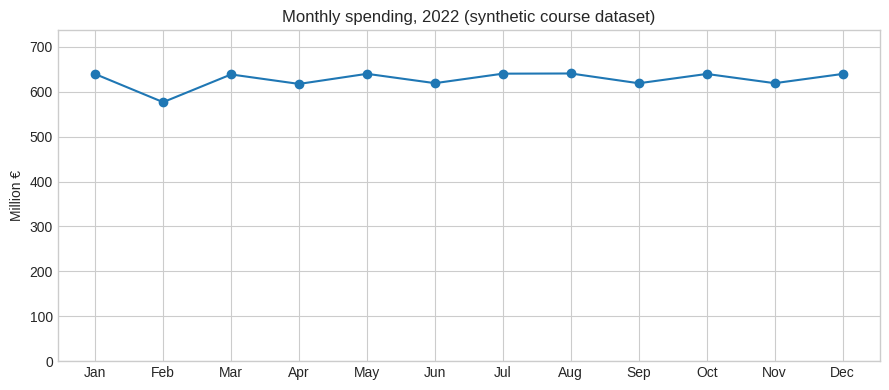

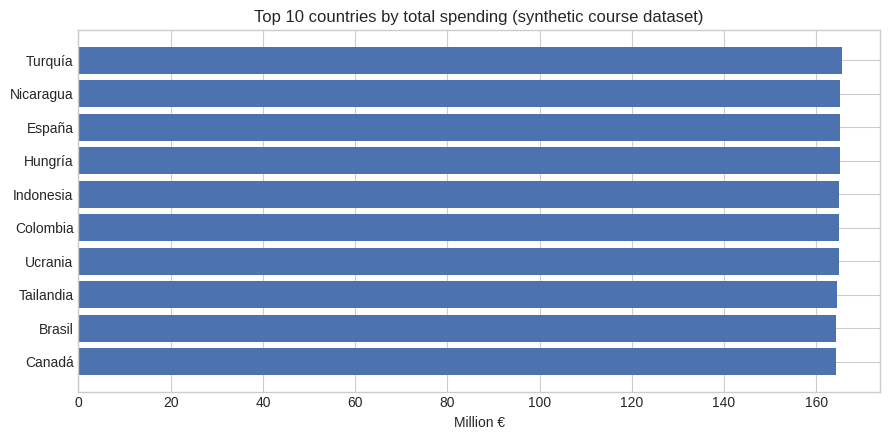

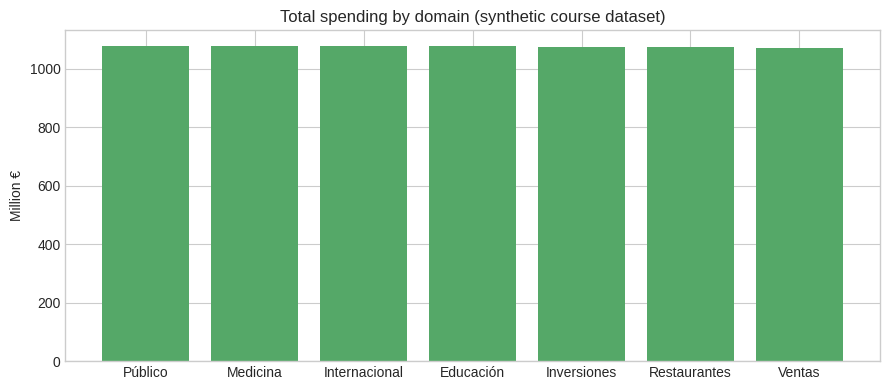

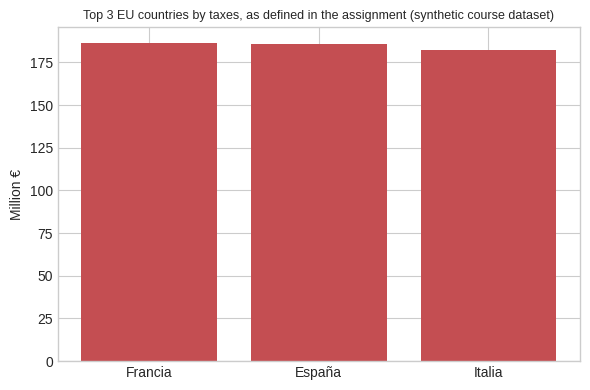

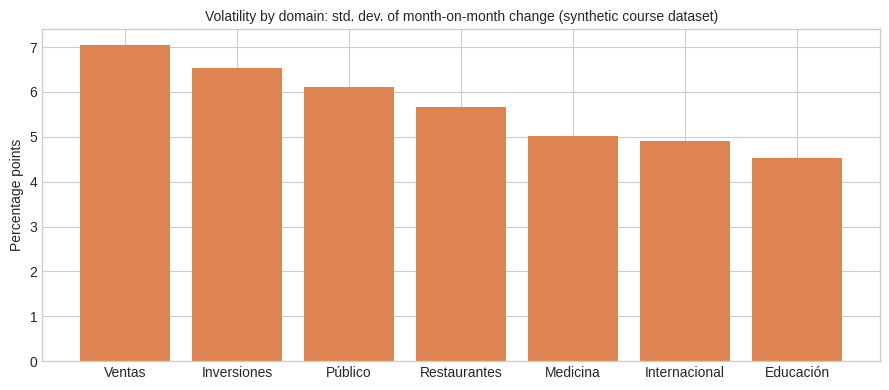

In [27]:
plt.style.use("seaborn-v0_8-whitegrid")
NOTE = "synthetic course dataset"

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=120)
    plt.show()

month = exported["gastos_por_mes"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(month["Mes"], month["Gasto_Acumulado"] / 1e6, marker="o")
ax.set_ylim(0, month["Gasto_Acumulado"].max() / 1e6 * 1.15)
ax.set_xticks(range(1, 13)); ax.set_xticklabels([m[:3] for m in MONTHS])
ax.set(title=f"Monthly spending, 2022 ({NOTE})", ylabel="Million €")
save(fig, "gasto_mensual")

top10 = exported["gastos_por_pais"].head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top10["País"], top10["Gasto_Acumulado"] / 1e6, color="#4c72b0")
ax.set(title=f"Top 10 countries by total spending ({NOTE})", xlabel="Million €")
save(fig, "top10_paises_gasto")

dom = exported["gastos_por_dominio"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(dom["Dominio"], dom["Gasto_Acumulado"] / 1e6, color="#55a868")
ax.set(title=f"Total spending by domain ({NOTE})", ylabel="Million €")
save(fig, "gasto_por_dominio")

tax = exported["top3_paises_impuestos"]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(tax["País"], tax["Total_Impuestos"] / 1e6, color="#c44e52")
ax.set(title=f"Top 3 EU countries by taxes, as defined in the assignment ({NOTE})", ylabel="Million €")
ax.title.set_fontsize(9)
save(fig, "top3_impuestos_ue")

vol = exported["volatilidad_dominio"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(vol["Dominio"], vol["Indice_Volatilidad"], color="#dd8452")
ax.set(title=f"Volatility by domain: std. dev. of month-on-month change ({NOTE})", ylabel="Percentage points")
ax.title.set_fontsize(10)
save(fig, "volatilidad_dominio")

In [28]:
spark.stop()